In [1]:
from tensorflow.keras.models import Model,load_model
from tensorflow.keras.layers import Input, Dense, Embedding, Concatenate, LayerNormalization, Dropout, RepeatVector, Reshape, Lambda,  MultiHeadAttention, GlobalAveragePooling1D
import torch
import torch.nn as nn
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd
import datetime
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
import yfinance as yf
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
def compute_rsi(series, period=14):
        delta = series.diff()
        gain = delta.clip(lower=0)
        loss = -delta.clip(upper=0)

        avg_gain = gain.rolling(window=period).mean()
        avg_loss = loss.rolling(window=period).mean()

        rs = avg_gain / avg_loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

In [3]:
nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\dhruv\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [4]:
news_df=pd.read_csv("dataset/raw_analyst_ratings.csv")
news_df['date'] = news_df['date'].astype(str).str.strip().str.split(' ').str[0]
news_df['stock']= news_df['stock'].astype(str).str.strip().str.upper()
news_df.head()

,headline,date,stock
0,Stocks That Hit 52-Week Highs On Friday,2020-06-05,A
1,Stocks That Hit 52-Week Highs On Wednesday,2020-06-03,A
2,71 Biggest Movers From Friday,2020-05-26,A
3,46 Stocks Moving In Friday's Mid-Day Session,2020-05-22,A
4,B of A Securities Maintains Neutral on Agilent...,2020-05-22,A


In [5]:
def fetch_news_sentiment(stock, date):
    # Convert date to datetime.date object
    date = pd.to_datetime(date).date()
    
    # print(f"Searching for stock: {stock} on date: {date}")
    
    # Filter news - using string formatting in query
    filtered_news = news_df.query(f'stock == "{stock}" and date == "{date}"')
    # print(f"Found {len(filtered_news)} news items")
    if(len(filtered_news)==0):
        date_str = date.strftime("%d-%m-%Y")  # Convert to YYYY-MM-DD
        filtered_news = news_df.query(f'stock == "{stock}" and date == "{date_str}"')
        
    
    # if len(filtered_news) > 0:
    #     print(filtered_news[['stock', 'date', 'headline']].head())
    
    # Calculate sentiment scores using VADER
    if not filtered_news.empty:
        sentiment_scores = filtered_news['headline'].apply(lambda x: sia.polarity_scores(str(x))['compound'])
        return sentiment_scores.max()  # Return maximum compound score
    else:
        return 0 

# Preparing Dataset

#### It can take upto 30 min so you can skip this step and directly run next step of loading the data from CSV

In [ ]:
stocks= [
    "ORCL","GOOGL","PG","JNJ","KO"
]

data=[]
for i,stock in enumerate(stocks):
    stock_history = yf.download(stock,  start='2011-01-01',end='2020-12-31')
    stock_history[('SMA_50',stock)] = stock_history['Close'].rolling(window=50).mean()
    stock_history[('SMA_200',stock)] = stock_history['Close'].rolling(window=200).mean()
    def compute_rsi(series, period=14):
        delta = series.diff()
        gain = delta.clip(lower=0)
        loss = -delta.clip(upper=0)

        avg_gain = gain.rolling(window=period).mean()
        avg_loss = loss.rolling(window=period).mean()

        rs = avg_gain / avg_loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

    stock_history[('RSI',stock)] = compute_rsi(stock_history['Close'])
    ema_12 = stock_history['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = stock_history['Close'].ewm(span=26, adjust=False).mean()
    stock_history[('MACD',stock)] = ema_12 - ema_26
    stock_history[('MACD_Signal',stock)] = stock_history['MACD'].ewm(span=9, adjust=False).mean()
    ma_20 = stock_history['Close'].rolling(window=20).mean()
    std_20 = stock_history['Close'].rolling(window=20).std()
    # stock_history[('Bollinger_Upper',stock)] = ma_20 + (2 * std_20)
    # stock_history[('Bollinger_Lower',stock)] = ma_20 - (2 * std_20)
    low_14 = stock_history['Low'].rolling(window=14).min()
    high_14 = stock_history['High'].rolling(window=14).max()
    stock_history[('%K',stock)] = 100 * ((stock_history['Close'] - low_14) / (high_14 - low_14))
    stock_history[('%D',stock)] = stock_history['%K'].rolling(window=3).mean()
    stock_history[('Volatility_14',stock)] = stock_history['Close'].rolling(window=14).std()
    stock_history = stock_history.stack(level=1).reset_index()
    for lag in [1,2,3]:
        stock_history[f'Close_lag_{lag}'] = stock_history.groupby('Ticker')['Close'].shift(lag)
        stock_history[f'Volume_lag_{lag}'] = stock_history.groupby('Ticker')['Volume'].shift(lag)

    # ==== Rolling Statistics ====
    for window in [5,20]:
        stock_history[f'RollingMean_{window}'] = stock_history.groupby('Ticker')['Close'].transform(lambda x: x.rolling(window).mean())
        stock_history[f'RollingStd_{window}'] = stock_history.groupby('Ticker')['Close'].transform(lambda x: x.rolling(window).std())
        stock_history[f'RollingVol_{window}'] = stock_history.groupby('Ticker')['Volume'].transform(lambda x: x.rolling(window).mean())

    # ==== Log Returns ====
    # stock_history['LogReturn_1'] = stock_history.groupby('Ticker')['Close'].transform(lambda x: np.log(x / x.shift(1)))
    # stock_history['LogReturn_5'] = stock_history.groupby('Ticker')['Close'].transform(lambda x: np.log(x / x.shift(5)))

    # ==== Relative Volume ====
    # stock_history['RelVolume_20'] = stock_history['Volume'] / (stock_history.groupby('Ticker')['Volume'].transform(lambda x: x.rolling(20).mean()))

    # ==== Seasonality Features ====
    # stock_history['DayOfWeek'] = stock_history['Date'].dt.dayofweek
    stock_history['Ticker']=stock
    stock_history['Target_7d'] = stock_history['Close'].shift(-5) # named 7 days as there will be no saturday and sunday in dataset but for same day next week the date counts
    stock_history['LogReturn_5d'] = np.log(stock_history['Target_7d'] / stock_history['Close'])
    sentiment_list = []
    # print(len(stock_history['Date']))
    for date in stock_history['Date']:
        score = fetch_news_sentiment(stock,date)
        sentiment_list.append(score)
    stock_history['sentiment_score']=sentiment_list
    stock_history.dropna(inplace=True)
    data.append(stock_history)


df = pd.concat(data)
df.reset_index()
df

C:\Users\dhruv\AppData\Local\Temp\ipykernel_21736\1467248461.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_history = yf.download(stock,  start='2011-01-01',end='2020-12-31')
[*********************100%***********************]  1 of 1 completed
C:\Users\dhruv\AppData\Local\Temp\ipykernel_21736\1467248461.py:36: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  stock_history = stock_history.stack(level=1).reset_index()
C:\Users\dhruv\AppData\Local\Temp\ipykernel_21736\1467248461.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_history = yf.download(stock,  start='2011-01-01',end='2020-12-31')
[*********************100%***********************]  1 of 1 completed
C:\Users\dhruv\AppData\Local\Temp\ipy

Price,Date,Ticker,Close,High,Low,Open,Volume,SMA_50,SMA_200,RSI,...,Close_lag_3,Volume_lag_3,RollingMean_5,RollingStd_5,RollingVol_5,RollingMean_20,RollingStd_20,RollingVol_20,Target_7d,LogReturn_5d
199,2011-10-17,ORCL,25.650257,26.077351,25.420285,25.945938,25074700,23.119399,25.825390,57.785499,...,25.551699,30322800.0,25.668324,0.288780,26310980.0,24.451259,0.937233,40240095.0,26.997240,0.051181
200,2011-10-18,ORCL,26.184118,26.282679,25.272439,25.576332,29754800,23.216512,25.827384,66.766302,...,25.576328,27161500.0,25.824377,0.319339,27185400.0,24.598547,0.967566,39182165.0,26.586569,0.015253
201,2011-10-19,ORCL,25.863800,26.430521,25.666680,26.143054,25586300,23.281317,25.828348,62.474310,...,26.159485,23613200.0,25.886798,0.280905,26238100.0,24.681048,1.002738,36295560.0,26.611217,0.028489
202,2011-10-20,ORCL,25.896656,26.077349,25.362788,25.945936,25102300,23.365139,25.831270,71.109906,...,25.650257,25074700.0,25.950863,0.222942,25826260.0,24.814373,0.976602,34482105.0,27.646088,0.065370
203,2011-10-21,ORCL,26.381247,26.488021,26.134847,26.233408,32837700,23.438653,25.836085,82.404575,...,26.184118,29754800.0,25.995216,0.287526,27671160.0,24.948977,0.998629,33924405.0,27.670746,0.047722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2506,2020-12-16,KO,46.323254,46.969298,46.218487,46.794690,15679600,44.715789,41.382126,54.247118,...,46.576443,10638100.0,46.545007,0.280910,15380140.0,46.074960,0.532139,16172975.0,46.340721,0.000377
2507,2020-12-17,KO,46.506596,46.890730,46.401832,46.532786,12677300,44.787301,41.375174,57.704328,...,46.506596,22292000.0,46.583422,0.253286,15496140.0,46.121637,0.526712,16042930.0,46.655022,0.003186
2508,2020-12-18,KO,46.916924,47.004226,45.939121,46.340720,35480100,44.851426,41.376520,67.426718,...,47.004223,16193700.0,46.651518,0.293515,20464540.0,46.166308,0.555074,16957460.0,47.283592,0.007785
2509,2020-12-21,KO,46.104996,46.270871,45.380375,45.991500,14926600,44.893250,41.388158,55.806943,...,46.323254,15679600.0,46.571198,0.384067,18991460.0,46.190307,0.540628,16921510.0,47.257397,0.024688


In [6]:
df=pd.read_csv("dataset/output.csv")
df=df.drop("Adj Close", axis=1)

In [7]:
feature_cols=df.drop(['Date','Ticker','Target_7d','LogReturn_5d'],axis=1)

cols=feature_cols.columns
print(cols)
print(len(cols))
n_tickers = len(df['Ticker'].unique())
def squeeze_axis_1(x):
    return tf.squeeze(x, axis=1)

embedding_dim = 16

time_steps=30
n_features=len(cols)

ticker_input=Input(shape=(1,),name='ticker_input')
series_input=Input(shape=(time_steps,n_features))
ticker_embedding=Embedding(input_dim=n_tickers,output_dim=embedding_dim)(ticker_input)



ticker_embedding = Lambda(
    squeeze_axis_1,
    output_shape=(embedding_dim,)
)(ticker_embedding)

ticker_expanded=RepeatVector(time_steps)(ticker_embedding)
combined_input=Concatenate()([series_input,ticker_expanded])

x=LayerNormalization()(combined_input)
x=MultiHeadAttention(num_heads=4,key_dim=128)(x,x)
x=Dropout(0.5)(x)
x=LayerNormalization()(x)
x=Dense(64,activation='relu')(x)
x=GlobalAveragePooling1D()(x)
output=Dense(1)(x)
model=Model(inputs=[ticker_input,series_input],outputs=output)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()


Index(['Close', 'High', 'Low', 'Open', 'Volume', 'SMA_50', 'SMA_200', 'RSI',
       'MACD', 'MACD_Signal', '%K', '%D', 'Volatility_14', 'Close_lag_1',
       'Volume_lag_1', 'Close_lag_2', 'Volume_lag_2', 'Close_lag_3',
       'Volume_lag_3', 'RollingMean_5', 'RollingStd_5', 'RollingVol_5',
       'RollingMean_20', 'RollingStd_20', 'RollingVol_20', 'sentiment_score'],
      dtype='object')
26


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ticker_input        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 16)     │         80 │ ticker_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 16)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer         │ (None, 30, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 30, 16)    │          0 │ lambda[0][0]      │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 42)    │          0 │ input_layer[0][0… │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 42)    │         84 │ concatenate[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 42)    │     87,594 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 42)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 42)    │         84 │ dropout_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 64)    │      2,752 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ dense[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 90,659 (354.14 KB)

 Trainable params: 90,659 (354.14 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

ticker_id = {ticker: idx for idx, ticker in enumerate(df['Ticker'].unique())}
df['Ticker_ID'] = df['Ticker'].map(ticker_id)
X_series, X_ticker, y = [], [], []

samples_per_ticker = {}
for ticker_id in df['Ticker_ID'].unique():
    ticker_df = df[df['Ticker_ID'] == ticker_id]
    sample_count = len(ticker_df) - time_steps
    samples_per_ticker[ticker_id] = sample_count
num_samples=sum(samples_per_ticker.values())

# scaler = StandardScaler()
# df[cols] = scaler.fit_transform(df[cols])
for ticker_id in df['Ticker_ID'].unique():
    ticker_df = df[df['Ticker_ID'] == ticker_id].sort_values('Date')
    for i in range(len(ticker_df) - time_steps):
        X_slice = ticker_df.iloc[i:i+time_steps]
        y_value = ticker_df.iloc[i+time_steps]['LogReturn_5d']  # or 'Target_7d'
        X_series.append(X_slice[cols].values)
        X_ticker.append(ticker_id)
        y.append(y_value)

X_series = np.array(X_series)
X_ticker = np.array(X_ticker).reshape(-1, 1)  # shape: (samples, 1)
y = np.array(y) 

y_scaler = StandardScaler()
y_scaled = y_scaler.fit_transform(y.reshape(-1, 1))

joblib.dump(y_scaler,"../stock_prediction_backend/models/stock_model_orcl_aapl_amzn_googl2022_New1.joblib")
print(X_series.shape)
n_samples, n_steps, n_features = X_series.shape
print(n_features)
# Reshape to 2D: (samples * time_steps, features)
X_series_2d = X_series.reshape(-1, n_features)
# Fit and transform
X_series_scaler = StandardScaler()

X_series_2d_scaled = X_series_scaler.fit_transform(X_series_2d)
# Reshape back to 3D
X_series_scaled = X_series_2d_scaled.reshape(n_samples, n_steps, n_features)
print(X_series_scaled.shape)

joblib.dump(X_series_scaler, "../stock_prediction_backend/models/X_series_scaler_multistock_US_New1.joblib")
print(y)

# from sklearn.model_selection import train_test_split

X_series_train, X_series_test, X_ticker_train, X_ticker_test, y_train, y_test = train_test_split(
    X_series_scaled, X_ticker, y_scaled, test_size=0.2, random_state=42
)




(11410, 30, 26)
26
(11410, 30, 26)
[ 0.06476955  0.00604247 -0.0298051  ...  0.00778514  0.02468779
  0.0313459 ]


In [ ]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)

model.fit([X_ticker_train, X_series_train], y_train, epochs=50, batch_size=64, callbacks=[early_stop], validation_split=0.2)

In [12]:
def squeeze_axis_1(x):
    return tf.squeeze(x, axis=1)


model = load_model(
    "../stock_prediction_backend/models/stock_model_multi_US_2022_sentiment_score.keras",
    custom_objects={'squeeze_axis_1': squeeze_axis_1},
    safe_mode=False
)

In [13]:
y_pred = model.predict([X_ticker_test, X_series_test])


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


In [14]:
predicted_log=y_scaler.inverse_transform(y_pred)
close_idx = list(cols).index("Close")


n_samples, n_steps, n_features = X_series_test.shape
X_series_test_2d = X_series_test.reshape(-1, n_features)


X_series_test_original_2d = X_series_scaler.inverse_transform(X_series_test_2d)


X_series_test_original = X_series_test_original_2d.reshape(n_samples, n_steps, n_features)
last_close = X_series_test_original[:, -1, close_idx]
predicted_price=predicted_log
predicted_price.shape


(2282, 1)

In [15]:
actual_log=y_scaler.inverse_transform(y_test)


close_original=actual_log
close_original.shape

(2282, 1)

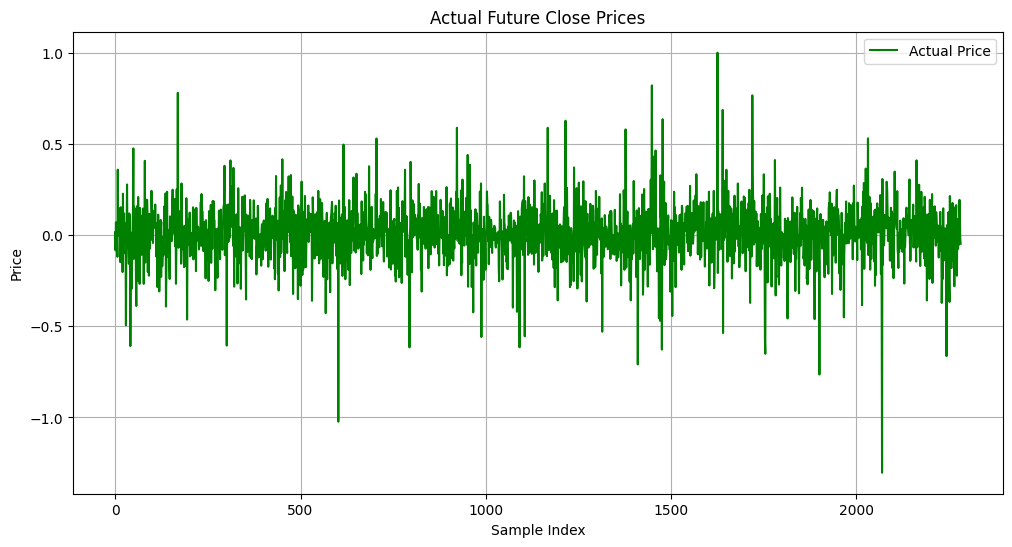

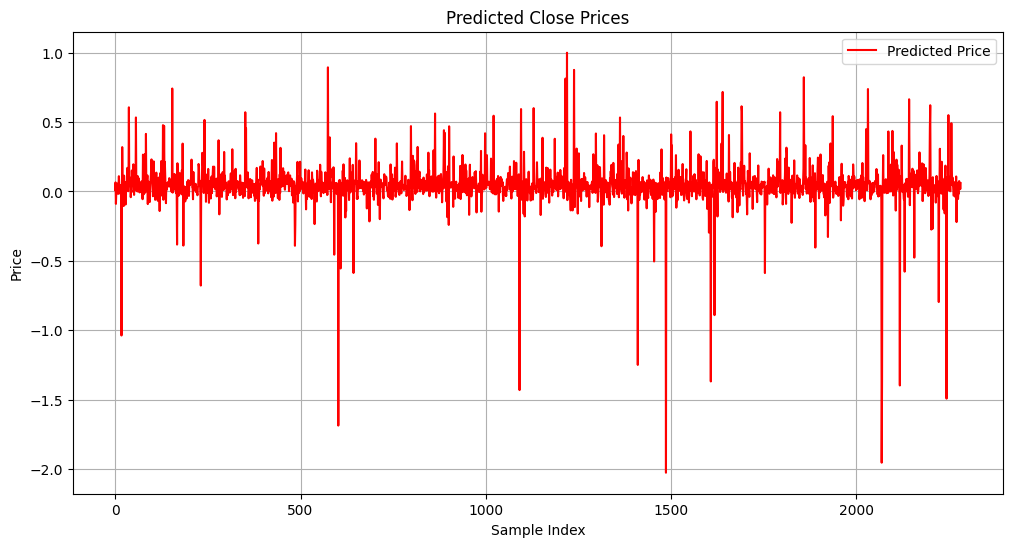

In [16]:
plt.figure(figsize=(12,6))
plt.plot(close_original/close_original.max(), label='Actual Price', color='green')
# plt.plot(predicted_price/predicted_price.max(), label='Predicted Price', color='red')
plt.title("Actual Future Close Prices")
plt.xlabel("Sample Index")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.figure(figsize=(12,6))
# plt.plot(close_original/close_original.max(), label='Actual Price', color='green')
plt.plot(predicted_price/predicted_price.max(), label='Predicted Price', color='red')
plt.title("Predicted Close Prices")
plt.xlabel("Sample Index")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
mae = mean_absolute_error(close_original, predicted_price)
print(f"MAE: {mae:.2f}")


MAE: 0.02


In [18]:
rmse = np.sqrt(mean_squared_error(close_original, predicted_price))
print(f"RMSE: {rmse:.2f}")

RMSE: 0.03


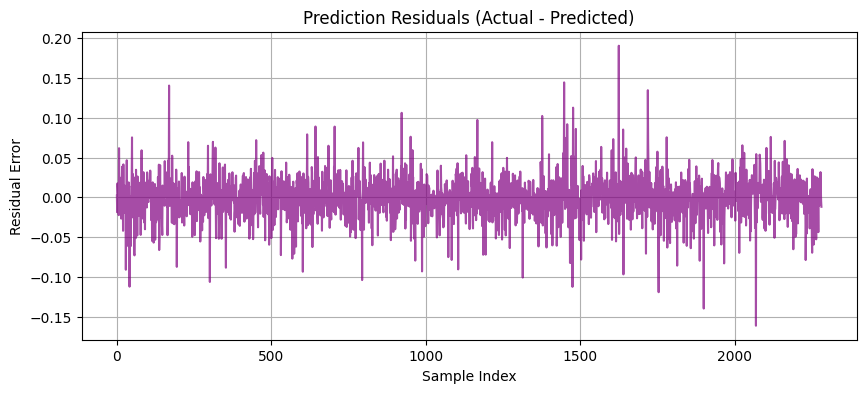

In [19]:
errors = close_original - predicted_price

plt.figure(figsize=(10, 4))
plt.plot(errors, color='purple', alpha=0.7)
plt.title('Prediction Residuals (Actual - Predicted)')
plt.xlabel('Sample Index')
plt.ylabel('Residual Error')
plt.grid(True)
plt.show()


In [20]:
results = pd.DataFrame({
    'ticker': X_ticker_test.flatten(),
    'actual': close_original.flatten(),
    'predicted': predicted_price.flatten()
})

ticker_metrics = results.groupby('ticker').apply(
    lambda x: pd.Series({
        'MAE': mean_absolute_error(x['actual'], x['predicted']),
        'RMSE': mean_squared_error(x['actual'], x['predicted'])
    })
).sort_values('RMSE')

print(ticker_metrics)


             MAE      RMSE
ticker                    
2       0.014405  0.000379
3       0.016946  0.000554
4       0.017525  0.000710
0       0.021629  0.000900
1       0.023775  0.000978


C:\Users\dhruv\AppData\Local\Temp\ipykernel_36276\1496834749.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ticker_metrics = results.groupby('ticker').apply(


In [87]:
model.save("models/stock_model_multi_US_2022_sentiment_score_price_predict.keras")